### Read asteroid data

In [ ]:
df_all = pd.read_csv(data_dir + 'X05_simplified.csv')
df_all.info()


/var/folders/xn/75ncx53144919w099wx5x5mw0000gn/T/ipykernel_24065/4049505335.py:1: DtypeWarning: Columns (1: permid) have mixed types. Specify dtype option on import or set low_memory=False.
  df_all = pd.read_csv(data_dir + 'X05_simplified.csv')


<class 'pandas.DataFrame'>
RangeIndex: 8078546 entries, 0 to 8078545
Data columns (total 10 columns):
 #   Column  Dtype  
---  ------  -----  
 0   provid  str    
 1   permid  object 
 2   ra      float64
 3   dec     float64
 4   rmsra   float64
 5   rmsdec  float64
 6   mag     float64
 7   rmsmag  float64
 8   band    str    
 9   mjdobs  float64
dtypes: float64(7), object(1), str(2)
memory usage: 704.3+ MB


In [ ]:
len(df_all), len(df_all['provid'].dropna()),  len(df_all['permid'].dropna())

(8078546, 7963802, 4788280)

In [ ]:
len(df_all['provid'].dropna().unique())

300992

### Representación gráfica del fit en $\theta_0$

El parámetro $\theta_0$ es el **ángulo de fase rotacional inicial** del asteroide en la primera observación ($t = t_0$):
$$\theta(t) = \left[2\pi \cdot \mathrm{fase}(t) + \theta_0\right] \pmod{360^\circ}$$

En el modelo analítico:
* $\theta = 0^\circ$ y $\theta = 180^\circ$: Las dos esferas están alineadas perpendicularmente a la línea de visión (**máxima área proyectada**, máximo brillo).
* $\theta = 90^\circ$ y $\theta = 270^\circ$: Ocurren los eclipses / ocultaciones mutuas a lo largo de la línea de visión (**mínima área proyectada**, mínimo brillo).
* $\theta_0 = 231.0^\circ$: Fija la orientación en la que se encontraba el objeto al comenzar la serie temporal (descendiendo del segundo máximo hacia el segundo eclipse).
* Debido a la simetría rotacional de dos esferas similares ($q \approx 0.87$), existe una solución equivalente separada por $180^\circ$ ($\theta_0 \approx 51.0^\circ$).

/var/folders/xn/75ncx53144919w099wx5x5mw0000gn/T/ipykernel_55303/2714165173.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


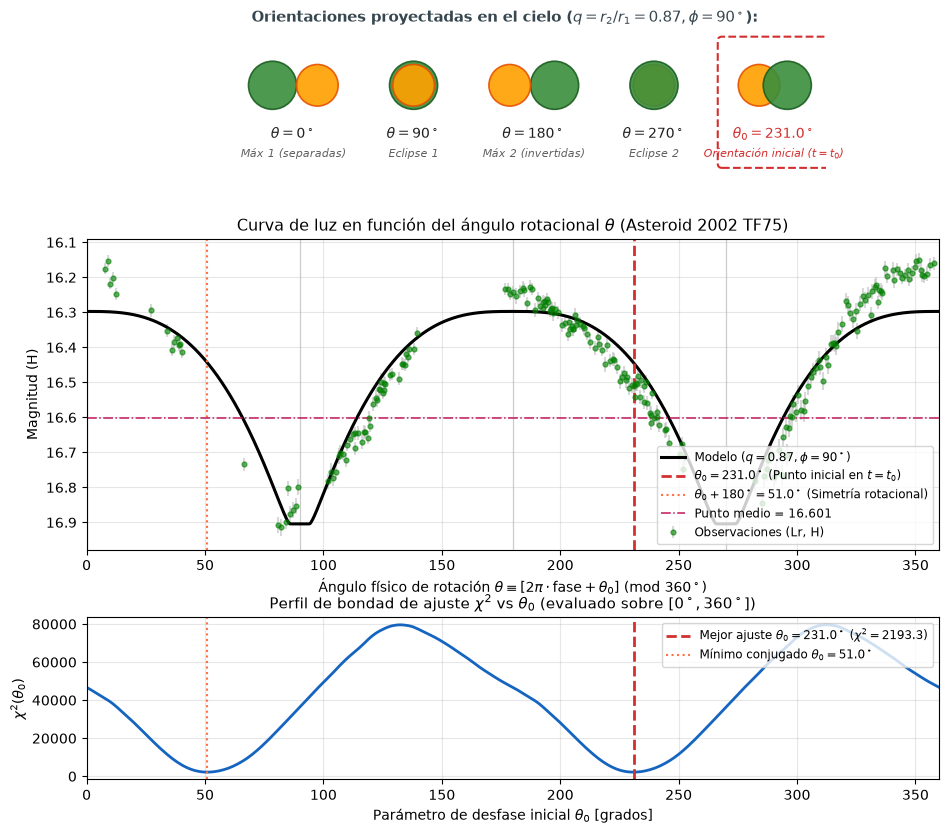

In [ ]:
from matplotlib.patches import Circle, FancyBboxPatch
import matplotlib.gridspec as gridspec

# 1. Ángulo rotacional físico theta para cada observación y para la grilla del modelo
ph_data = sph_phase(sph_t, freq_fit)
theta_data = np.mod(2 * np.pi * ph_data + theta0, 2 * np.pi) / DEG

theta_grid = np.linspace(0, 360, 1000)
theta_rad = theta_grid * DEG
# Función de magnitud directamente en theta
m_grid_theta = m_sep - 2.5 * np.log10(
    touching_spheres_area(theta_rad, q_fit, np.arccos(np.sqrt(np.clip(cos2phi, 0, 1)))) / (np.pi * (1.0 + q_fit**2))
)

# 2. Escaneo de chi^2 en función de theta_0 sobre [0, 360] deg (manteniendo fijos los demás parámetros)
th0_scan = np.linspace(0, 360, 361)
chi2_scan = []
for th0_s in th0_scan:
    mod_s = touching_spheres_mag(ph_data, m_sep, q_fit, cos2phi, th0_s * DEG)
    chi2_scan.append(np.sum(((sph_y - mod_s) / sph_dy)**2))
chi2_scan = np.array(chi2_scan)

th0_deg = np.mod(theta0, 2 * np.pi) / DEG
th0_sym = np.mod(th0_deg + 180, 360)

# 3. Gráfica integrada: Geometría + Curva de Luz en theta + Perfil chi^2
fig = plt.figure(figsize=(11, 10))
gs = gridspec.GridSpec(3, 1, height_ratios=[1.2, 2.3, 1.2], hspace=0.32)

# --- PANEL 1: Esquema geométrico en el plano del cielo ---
ax_geom = fig.add_subplot(gs[0])
ax_geom.set_xlim(-1, 11)
ax_geom.set_ylim(-1.6, 1.5)
ax_geom.set_aspect('equal')
ax_geom.axis('off')

key_angles = [
    (0, r'$\theta = 0^\circ$', 'Máx 1 (separadas)', 0.8),
    (90, r'$\theta = 90^\circ$', 'Eclipse 1', 3.1),
    (180, r'$\theta = 180^\circ$', 'Máx 2 (invertidas)', 5.4),
    (270, r'$\theta = 270^\circ$', 'Eclipse 2', 7.7),
    (th0_deg, fr'$\theta_0 = {th0_deg:.1f}^\circ$', 'Orientación inicial ($t=t_0$)', 10.0)
]

r1_draw = 0.46
r2_draw = 0.46 * q_can

for angle_deg, title_lbl, sub_lbl, cx in key_angles:
    ang = angle_deg * DEG
    dx = (r1_draw + r2_draw) * np.cos(ang)
    c1_x = cx - dx * (r2_draw / (r1_draw + r2_draw))
    c2_x = cx + dx * (r1_draw / (r1_draw + r2_draw))
    
    z2 = np.sin(ang)
    if z2 >= 0:
        s1 = Circle((c1_x, 0.05), r1_draw, color='#388E3C', ec='#1B5E20', lw=1.2, alpha=0.9, zorder=2)
        s2 = Circle((c2_x, 0.05), r2_draw, color='#FFA000', ec='#E65100', lw=1.2, alpha=0.9, zorder=3)
    else:
        s2 = Circle((c2_x, 0.05), r2_draw, color='#FFA000', ec='#E65100', lw=1.2, alpha=0.9, zorder=2)
        s1 = Circle((c1_x, 0.05), r1_draw, color='#388E3C', ec='#1B5E20', lw=1.2, alpha=0.9, zorder=3)
    
    ax_geom.add_patch(s1)
    ax_geom.add_patch(s2)
    
    is_th0 = 'theta_0' in title_lbl
    ax_geom.text(cx, -0.75, title_lbl, ha='center', va='top', fontsize=10,
                 weight='bold' if is_th0 else 'medium',
                 color='#D32F2F' if is_th0 else '#212121')
    ax_geom.text(cx, -1.15, sub_lbl, ha='center', va='top', fontsize=8,
                 style='italic', color='#D32F2F' if is_th0 else '#616161')
    
    if is_th0:
        box = FancyBboxPatch((cx - 1.0, -1.45), 2.0, 2.35, boxstyle="round,pad=0.08",
                             fc='none', ec='#D32F2F', ls='--', lw=1.5)
        ax_geom.add_patch(box)

ax_geom.text(0.0, 1.25, fr"Orientaciones proyectadas en el cielo ($q = r_2/r_1 = {q_can:.2f}, \phi = {phi_fit / DEG:.0f}^\circ$):",
             fontsize=10.5, weight='bold', color='#37474F')

# --- PANEL 2: Curva de luz vs ángulo rotacional theta ---
ax_lc = fig.add_subplot(gs[1])
b = band if isinstance(band, str) else band[0]
curve_color = band_colors.get(b, '#2E7D32')
ax_lc.errorbar(theta_data, sph_y, yerr=sph_dy, fmt='o', ms=3.5, alpha=0.6,
               color=curve_color, ecolor='0.75', label=f'Observaciones ({band}, {prop})')
ax_lc.plot(theta_grid, m_grid_theta, 'k-', lw=2.2, label=fr'Modelo ($q={q_can:.2f}, \phi={phi_fit/DEG:.0f}^\circ$)')

ax_lc.axvline(th0_deg, color='#D32F2F', ls='--', lw=2.0,
              label=fr'$\theta_0 = {th0_deg:.1f}^\circ$ (Punto inicial en $t=t_0$)')
ax_lc.axvline(th0_sym, color='#FF7043', ls=':', lw=1.5,
              label=fr'$\theta_0 + 180^\circ = {th0_sym:.1f}^\circ$ (Simetría rotacional)')

for ang in [0, 90, 180, 270, 360]:
    ax_lc.axvline(ang, color='0.8', ls='-', lw=0.9, zorder=0)

ax_lc.axhline(m_mid, color='#C2185B', ls='-.', lw=1.1, label=f'Punto medio = {m_mid:.3f}')
ax_lc.set_xlim(0, 360)
ax_lc.invert_yaxis()
ax_lc.set_xlabel(r'Ángulo físico de rotación $\theta \equiv [2\pi \cdot \mathrm{fase} + \theta_0]\ (\mathrm{mod}\ 360^\circ)$')
ax_lc.set_ylabel('Magnitud (H)')
ax_lc.set_title(f"Curva de luz en función del ángulo rotacional $\\theta$ (Asteroid {provid})", fontsize=11.5)
ax_lc.grid(True, alpha=0.3)
ax_lc.legend(loc='lower right', frameon=True, fontsize=8.5)

# --- PANEL 3: Perfil de chi^2 vs theta_0 ---
ax_chi2 = fig.add_subplot(gs[2])
ax_chi2.plot(th0_scan, chi2_scan, color='#1565C0', lw=2)
ax_chi2.axvline(th0_deg, color='#D32F2F', ls='--', lw=2.0,
                label=fr'Mejor ajuste $\theta_0 = {th0_deg:.1f}^\circ$ ($\chi^2 = {chi2_scan.min():.1f}$)')
ax_chi2.axvline(th0_sym, color='#FF7043', ls=':', lw=1.5,
                label=fr'Mínimo conjugado $\theta_0 = {th0_sym:.1f}^\circ$')

ax_chi2.set_xlim(0, 360)
ax_chi2.set_xlabel(r'Parámetro de desfase inicial $\theta_0$ [grados]')
ax_chi2.set_ylabel(r'$\chi^2(\theta_0)$')
ax_chi2.set_title(r'Perfil de bondad de ajuste $\chi^2$ vs $\theta_0$ (evaluado sobre $[0^\circ, 360^\circ]$)', fontsize=11)
ax_chi2.grid(True, alpha=0.3)
ax_chi2.legend(loc='upper right', frameon=True, fontsize=8.5)

fig.tight_layout()
fig.savefig(fig_dir + f"theta0_representation_{provid.replace(' ', '_')}.png", dpi=300)
plt.show()